# Проверка качества данных

Таблица `events`: события магазина косметики REES46, декабрь 2019 — январь 2020.

In [1]:
import duckdb
from pathlib import Path

# корень проекта: ноутбук может запускаться и из notebooks/, и из корня
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent

# read_only: базу можно читать одновременно из ноутбука и из терминала
con = duckdb.connect(str(ROOT / 'data/processed/shop.duckdb'), read_only=True)

def q(sql):
    """Выполнить SQL и показать результат таблицей."""
    return con.sql(sql).df()

q("SELECT COUNT(*) AS rows, COUNT(DISTINCT user_id) AS users FROM events")

,rows,users
0,7798038,725736


## Задача 1. Полнота: где пропуски?

Прежде чем считать путь покупателя (воронку: посмотрел → положил в корзину → купил) и удержание, проверяю, можно ли доверять данным. Первый вопрос — в каких столбцах есть пропуски.

Сначала посмотрела, как выглядят строки без бренда: пустое значение отображается как `None` (в SQL это `NULL`).

In [2]:
q("""
SELECT *
FROM events
WHERE brand IS  NULL
  LIMIT 10
""")

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-12-01 00:00:07,view,5824148,1487580005511725929,None,None,5.56,576005683,28172809-7e4a-45ce-bab0-5efa90117cd5
1,2019-12-01 00:00:18,cart,5629988,1487580009311764506,None,None,1.19,579966747,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b
2,2019-12-01 00:00:40,cart,5755170,1487580009387261981,None,None,2.79,579751441,8de492d7-0937-47ae-be2c-a7615aec2b0d
3,2019-12-01 00:00:45,cart,5755170,1487580009387261981,None,None,2.79,579751441,8de492d7-0937-47ae-be2c-a7615aec2b0d
4,2019-12-01 00:00:46,cart,5755170,1487580009387261981,None,None,2.79,579751441,8de492d7-0937-47ae-be2c-a7615aec2b0d
5,2019-12-01 00:01:01,view,5832416,1487580009471148064,None,None,0.95,576802932,01dbbcc3-b26b-4bed-bce4-1b506725a351
6,2019-12-01 00:01:15,cart,5904369,1487580007675986893,None,None,1.59,348405118,722ffea5-73c0-4924-8e8f-371ff8031af4
7,2019-12-01 00:01:16,view,5881896,1487580011903844485,None,None,3.63,537197314,1fc5bdf5-a94f-4e5f-8283-215b3fed14c1
8,2019-12-01 00:01:22,view,5847872,1487580006317032337,None,None,7.94,576802932,d3809963-53ce-47fd-88c0-21afda8c90ca
9,2019-12-01 00:01:34,remove_from_cart,5847872,1487580006317032337,None,None,7.94,576802932,51d85cb0-897f-48d2-918b-ad63965c12dc


Считаю, сколько строк заполнено в каждом столбце. `COUNT(*)` считает все строки, `COUNT(столбец)` — только строки, где значение не `NULL`.

In [3]:
q("""
SELECT 
  COUNT(*)  as total,
  COUNT(category_code)  as category_code_filled,
  COUNT(brand)  as brand_filled,
  COUNT(price)  as price_filled,
  COUNT(user_id)  as user_id_filled,
  COUNT(user_session)  as user_session
FROM events
""")


,total,category_code_filled,brand_filled,price_filled,user_id_filled,user_session
0,7798038,133184,4512119,7798038,7798038,7795945


И то же самое в процентах пропусков: `100.0 * (COUNT(*) - COUNT(столбец)) / COUNT(*)`.

In [4]:
q("""
SELECT 
  (100.0 * (COUNT(*) -  COUNT(category_code))/COUNT(*)) as category_code_missing,
  (100.0 * (COUNT(*) -  COUNT(brand))/COUNT(*)) as brand_missing,
  (100.0 * (COUNT(*) -  COUNT(price))/COUNT(*)) as price_missing, 
  (100.0 * (COUNT(*) -  COUNT(user_id))/COUNT(*)) as user_id_missing, 
  (100.0 * (COUNT(*) -  COUNT(user_session))/COUNT(*)) as user_session_missing
from events
""")

,category_code_missing,brand_missing,price_missing,user_id_missing,user_session_missing
0,98.292083,42.137766,0.0,0.0,0.02684


### Что видно по пропускам

- **Код категории (`category_code`) пуст в 98% строк.** Но это не мешает: `category_id` заполнен полностью, поэтому категории можно сравнивать по ID. Код категории был бы полезен для понятных названий, но в этом анализе он не нужен.
- **Бренд (`brand`) пуст в 42% строк.** Это много — дальше проверяю, случайные ли это пропуски.
- **Цена и пользователь заполнены везде.** Каждое действие связано с товаром, у которого есть цена, и с человеком, который это действие совершил. Значит, путь покупателя и удержание можно считать по всем событиям.
- **Сессия (`user_session`) пуста в 0,03% строк (2 093 события).** Это редкие случайные пропуски — в расчётах по сессиям их не учитываю, в расчётах по пользователям оставляю. Сама сессия полезна: она показывает, что действия совершены за один визит.

## Случайны ли пропуски бренда?

Дальше мне захотелось узнать: пропуски в этих 42% случайные или нет? Это может быть товар, у которого бренд есть, но не указан, или no-name товар. Сравниваю события с брендом и без по цене и по долям типов событий (`_pct` — процент от всех событий группы).

In [5]:
q("""
SELECT
    CASE WHEN brand IS NULL THEN 'бренд неизвестен' ELSE 'бренд указан' END AS brand_group,
    COUNT(*)                     AS events,
    ROUND(AVG(price), 2)         AS avg_price,
    ROUND(MEDIAN(price), 2)      AS median_price,
    ROUND(100.0 * SUM(CASE WHEN event_type = 'view'     THEN 1 ELSE 0 END) / COUNT(*), 1) AS view_pct,
    ROUND(100.0 * SUM(CASE WHEN event_type = 'cart'     THEN 1 ELSE 0 END) / COUNT(*), 1) AS cart_pct,
    ROUND(100.0 * SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) / COUNT(*), 2) AS purchase_pct,
    COUNT(DISTINCT category_id)  AS categories
FROM events
GROUP BY brand_group
""")

,brand_group,events,avg_price,median_price,view_pct,cart_pct,purchase_pct,categories
0,бренд неизвестен,3285919,7.47,4.05,47.0,27.1,6.19,382
1,бренд указан,4512119,9.75,4.21,49.2,26.3,6.06,414


### Что видно

- **Поведение почти одинаковое.** Доли просмотров, добавлений в корзину и покупок отличаются не больше чем на 2 п.п.
- **Медианная цена почти одинаковая (4,05 и 4,21), а средняя выше у товаров с брендом (9,75 против 7,47).** Типичный товар в обеих группах похож. Среднее поднимают единичные дорогие товары, а у дорогих товаров бренд чаще указан.
- **Доказать, что пропуски случайные, нельзя.** Значения очень близкие, но товары без бренда могут отличаться тем, чего нет в данных.

## Пропуск бренда — свойство товара или сбой записи?

Проверяю на уровне товара: бывает ли у одного `product_id` бренд то указан, то нет. Сначала собираю одну строку на товар (`WITH products`), потом делю товары на три группы.

`MAX(brands)` — самое большое число разных брендов у одного товара в группе. Если больше 1, значит, у какого-то товара несколько брендов.

In [6]:
q("""
WITH products AS (
    SELECT
        product_id,
        COUNT(*)              AS events,       -- всего событий с товаром
        COUNT(brand)          AS with_brand,   -- из них с указанным брендом
        COUNT(DISTINCT brand) AS brands        -- сколько разных брендов встречается
    FROM events
    GROUP BY product_id
)
SELECT
    CASE
        WHEN with_brand = 0      THEN 'бренд не указан никогда'
        WHEN with_brand = events THEN 'бренд указан всегда'
        ELSE 'то указан, то нет'
    END                  AS product_group,
    COUNT(*)             AS products,
    SUM(events)          AS events,
    MAX(brands)          AS max_brands_per_product
FROM products
GROUP BY product_group
ORDER BY products DESC
""")

,product_group,products,events,max_brands_per_product
0,бренд указан всегда,25699,4333375.0,2
1,бренд не указан никогда,20811,3276046.0,0
2,"то указан, то нет",1792,188617.0,1


### Что видно

- **Почти у всех товаров бренд либо есть всегда, либо нет никогда.** Значит, пропуск бренда — это свойство товара в каталоге, а не случайная потеря событий. Отличить no-name товары от товаров с незаполненным брендом по этим данным нельзя.
- **У 1 792 товаров бренд то указан, то нет** — это и есть случайные пропуски при записи. Их можно восстановить по бренду того же товара (см. запрос ниже).
- **Максимальное число брендов у одного товара — 2.** Так быть не может: у товара только один бренд. Значит, в данных есть ошибка.

### Сколько пропусков можно восстановить
Берём товары, у которых бренд указан хотя бы раз, но не всегда, и считаем их события без бренда.


In [7]:
q("""
WITH products AS (
    SELECT
        product_id,
        COUNT(*)     AS events,
        COUNT(brand) AS with_brand
    FROM events
    GROUP BY product_id
)
SELECT
    COUNT(*)                 AS mixed_products,
    SUM(events)              AS mixed_events,
    SUM(events - with_brand) AS recoverable_missing_events,
    ROUND(100.0 * SUM(events - with_brand)
          / (SELECT COUNT(*) - COUNT(brand) FROM events), 2) AS pct_of_all_missing
FROM products
WHERE with_brand > 0 AND with_brand < events
""")

,mixed_products,mixed_events,recoverable_missing_events,pct_of_all_missing
0,1792,188617.0,9873.0,0.3


## Товары с двумя брендами

После этого я решила посмотреть, что это за товары, у которых несколько брендов.

In [8]:
q("""
SELECT
    product_id,
    STRING_AGG(DISTINCT brand, ', ') AS brands,
    COUNT(*)                         AS events
FROM events
WHERE brand IS NOT NULL
GROUP BY product_id
HAVING COUNT(DISTINCT brand) > 1
ORDER BY events DESC
""")

,product_id,brands,events
0,37042,"candy, runail",358
1,5739032,"kapous, finish",334
2,37072,"runail, candy",140
3,5683272,"swarovski, candy",104
4,5751412,"uno, candy",87
5,5877003,"lianail, candy",80
6,5877005,"candy, lianail",62
7,5877001,"candy, lianail",61
8,5876999,"lianail, candy",59
9,5877000,"candy, lianail",49


Таких товаров 21. Почти у всех один из брендов — `candy`. Проверяю, когда встречается каждый бренд.

_Этот запрос ещё не запускала._

In [9]:
q("""
WITH multi AS (
    SELECT product_id
    FROM events
    WHERE brand IS NOT NULL
    GROUP BY product_id
    HAVING COUNT(DISTINCT brand) > 1
)
SELECT
    e.product_id,
    e.brand,
    MIN(e.event_time)::date AS first_seen,
    MAX(e.event_time)::date AS last_seen,
    COUNT(*)                AS events
FROM events e
JOIN multi m ON m.product_id = e.product_id
WHERE e.brand IS NOT NULL
GROUP BY e.product_id, e.brand
ORDER BY e.product_id, first_seen
""")

,product_id,brand,first_seen,last_seen,events
0,37042,candy,2019-12-01,2019-12-04,23
1,37042,runail,2019-12-04,2020-01-31,335
2,37072,candy,2019-12-01,2019-12-02,9
3,37072,runail,2019-12-04,2020-01-31,131
4,5557820,candy,2019-12-03,2019-12-03,1
5,5557820,pnb,2019-12-06,2020-01-31,14
6,5683272,candy,2019-12-03,2019-12-03,1
7,5683272,swarovski,2019-12-05,2020-01-31,103
8,5739032,finish,2019-12-01,2019-12-03,19
9,5739032,kapous,2019-12-04,2020-01-31,315


### Что видно

Что видно в таблице:

1. **Бренды не встречаются одновременно, а сменяют друг друга.** Например, у товара 37042 `candy` — с 1 по 4 декабря, `runail` — с 4 декабря до конца января.
2. **Смена у всех товаров в начале декабря.** Случайные ошибки были бы разбросаны по всему периоду, а здесь похоже на одно исправление каталога.
3. **Старый бренд почти всегда `candy`, а новые разные** (runail, swarovski, uno, pnb, oniq). Один производитель не выпускает всё это сразу.
4. **Новый бренд держится до конца января, и у него почти все события** (335 против 23 у товара 37042).

**Гипотеза:** часть товаров по ошибке числилась за брендом `candy`, потом каталог исправили. Проверяю: есть ли у `candy` свои товары и когда он встречается на «двухбрендовых» товарах.

In [10]:
q("""
SELECT
    CASE WHEN product_id IN (
             SELECT product_id
             FROM events
             WHERE brand IS NOT NULL
             GROUP BY product_id
             HAVING COUNT(DISTINCT brand) > 1)
         THEN 'товары с двумя брендами'
         ELSE 'остальные товары'
    END                        AS products,
    COUNT(DISTINCT product_id) AS n_products,
    COUNT(*)                   AS events,
    MIN(event_time)::date      AS first_seen,
    MAX(event_time)::date      AS last_seen
FROM events
WHERE brand = 'candy'
GROUP BY products
""")

,products,n_products,events,first_seen,last_seen
0,остальные товары,15,107,2019-12-01,2020-01-22
1,товары с двумя брендами,17,96,2019-12-01,2019-12-13


### Вывод

`candy` — настоящий бренд, у него есть свои товары, и они встречаются до 22 января. А на товарах с двумя брендами `candy` встречается только до 13 декабря, потом его сменяет другой бренд.

Можно предположить, что это была просто ошибка в каталоге, которую потом исправили: там, где `candy` был указан неправильно, бренд всё равно поменялся. Точно мы этого не знаем, потому что истории каталога у нас нет, но ничего сверхъестественного здесь нет.

Масштаб: на этих товарах 96 событий с `candy` из 7,8 млн. Если допущение неверно, ошибка будет только в анализе по брендам. Для таких товаров беру последний бренд.

## Итог по брендам: где пропуски мешают, а где нет

**Не мешают:**
- путь покупателя и удержание по всему магазину — бренд в этих расчётах не используется;
- сравнение брендов между собой по конверсии — это доли, они почти не меняются, если часть товаров бренда без названия.

**Мешают, выводы только с оговоркой:**
- доля бренда в выручке магазина — часть выручки бренда «спряталась» в пропусках;
- рейтинг брендов по суммам (выручка, продажи) — сумма по части товаров меньше настоящей, и рейтинг может перевернуться;
- сравнение «брендовые против небрендовых» — в «без бренда» попадают и no-name товары, и брендовые с пропуском;
- анализ дорогого сегмента — у дорогих товаров бренд указан чаще.

## Задача 2. Полнота по дням

Число событий по каждому дню, по возрастанию даты.

In [11]:
q("""
SELECT
    DATE_TRUNC('day', event_time) AS day,
    COUNT(*) AS events
FROM events
GROUP BY day
ORDER BY  day  asc
""")

,day,events
0,2019-12-01,127579
1,2019-12-02,134714
2,2019-12-03,137687
3,2019-12-04,137253
4,2019-12-05,127346
...,...,...
57,2020-01-27,206611
58,2020-01-28,184379
59,2020-01-29,145257
60,2020-01-30,142843


<Axes: title={'center': 'События по дням'}, xlabel='day'>

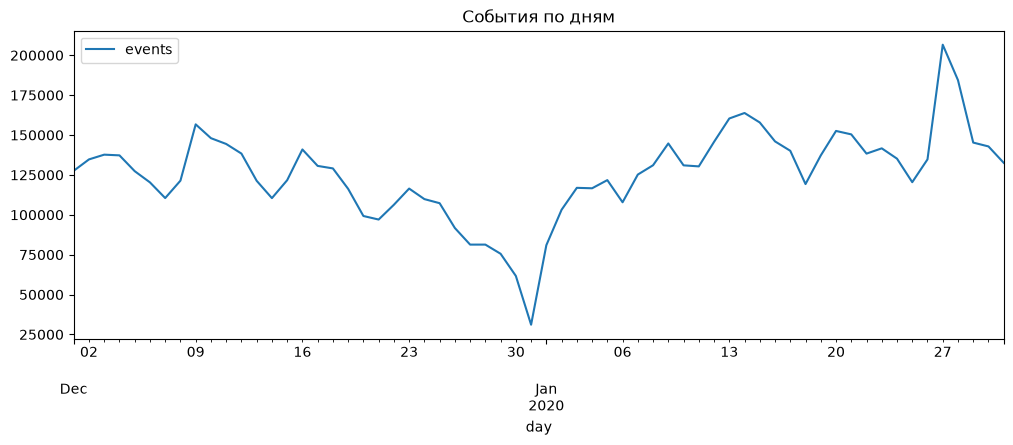

In [12]:
df = q("""
SELECT
    DATE_TRUNC('day', event_time) AS day,
    COUNT(*) AS events
FROM events
GROUP BY day
ORDER BY  day  asc
""")
df.plot(x='day', y='events', figsize=(12, 4), title='События по дням')

,weekday_number,weekday,days,avg_events,median_events
0,1,Monday,6,143616.0,146751.5
1,2,Tuesday,5,146113.0,148027.0
2,3,Wednesday,6,142027.0,141368.0
3,4,Thursday,7,136738.0,141652.0
4,5,Friday,7,125672.0,130991.0
5,6,Saturday,6,114662.0,114868.5
6,7,Sunday,7,127800.0,127579.0


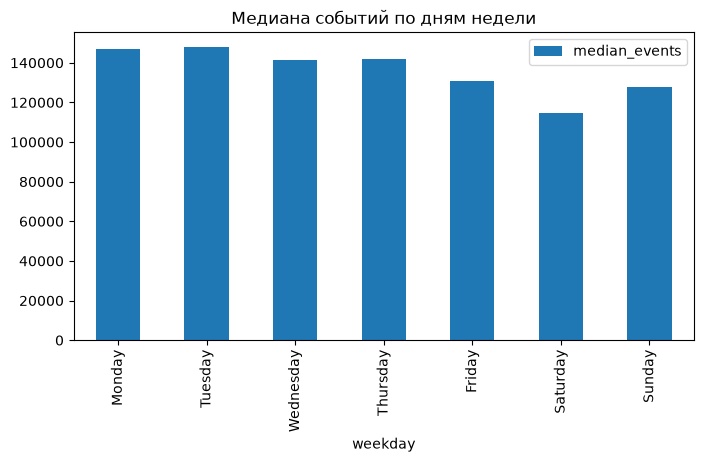

In [13]:
df_week = q("""
WITH daily AS (
    SELECT
        event_time::date AS day,
        COUNT(*)         AS events
    FROM events
    GROUP BY day
)
SELECT
    ISODOW(day)          AS weekday_number,
    DAYNAME(day)         AS weekday,
    COUNT(*)             AS days,
    ROUND(AVG(events))   AS avg_events,
    MEDIAN(events)       AS median_events
FROM daily
WHERE day NOT BETWEEN '2019-12-24' AND '2020-01-08'
  AND day NOT IN ('2020-01-27', '2020-01-28')
GROUP BY weekday_number, weekday
ORDER BY weekday_number
""")

df_week.plot(x='weekday', y='median_events', kind='bar', figsize=(8, 4), title='Медиана событий по дням недели')
df_week

### Вывод по дням

**Новый год.** В канун Нового года событий мало. Это можно объяснить тем, что праздник и в это время в магазин заходят реже. События есть в каждый час, поэтому это не похоже на сбой записи.

**Дни недели.** В понедельник и вторник у нас больше всего событий, меньше всего — в субботу: её медиана примерно на 22% ниже, чем во вторник (114 869 против 148 027). В целом всё достаточно тривиально, сбоев и заскоков по дням недели не видно. В этом расчёте нет новогоднего периода и 27–28 января.

**Что это значит для A/B-теста.** Если запустить тест только с понедельника по среду, мы не учтём дни, когда у нас меньше событий, и метрики могут получиться неправильными. Поэтому тест нужно держать полными неделями. Покупки и конверсию по дням недели мы отдельно пока не проверяли.

**27–28 января.** Здесь резкий всплеск событий, причина пока неизвестна. Дальше проверяю, не связан ли он с дублями.

## Задача 3. Дубли

Проверяю, нет ли одного и того же события, записанного несколько раз. Такие строки могут завысить число событий и исказить метрики, а ещё они могли создать всплеск 27–28 января.

Дубль — это строка, у которой совпадают все столбцы. `GROUP BY ALL` кладёт такие строки в одну группу, `copies` показывает, сколько их, а лишних строк в группе `copies - 1`.

**Результат: 389 232 события имеют дубли, лишних строк 408 960, это 5,24% таблицы.** Это не маленький результат, поэтому разбираюсь дальше.

In [14]:
q("""
WITH grouped AS (
    SELECT
        event_time, event_type, product_id, category_id,
        category_code, brand, price, user_id, user_session,
        COUNT(*) AS copies
    FROM events
    GROUP BY ALL
    HAVING copies>1 
)
SELECT
    COUNT(*)         AS duplicated_events,
    SUM(copies-1)    AS extra_rows,
    ROUND(100.0 * SUM(copies-1) / (SELECT COUNT(*) FROM events), 2) AS extra_rows_pct
FROM grouped
""")

,duplicated_events,extra_rows,extra_rows_pct
0,389232,408960.0,5.24


Посмотрела на конкретные строки с самым большим числом копий. В основном это `remove_from_cart`, но есть и `cart`. Время у копий одно и то же. Дальше считаю, какие именно события дублируются.

In [15]:
q("""
SELECT
    event_time, event_type, product_id, category_id,
    category_code, brand, price, user_id, user_session,
    COUNT(*) AS copies
FROM events
GROUP BY ALL
HAVING copies > 1
ORDER BY copies DESC
LIMIT 10
""")

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,copies
0,2020-01-12 12:39:18,remove_from_cart,5700082,1487580011585077370,None,NaN,16.51,245068553,1bdcb724-31d4-4afb-b969-2d9862a96b2f,29
1,2019-12-17 16:32:26,remove_from_cart,5587744,1487580006317032337,None,irisk,1.59,578765531,18fba739-d6aa-447c-abe6-86ef8ce9102e,20
2,2019-12-25 12:29:33,cart,5802433,1487580009286598681,None,NaN,0.35,543714981,f581c117-5ba6-4e91-bdb5-b50ec01e28b7,19
3,2020-01-12 12:39:33,remove_from_cart,5700082,1487580011585077370,None,NaN,16.51,245068553,1bdcb724-31d4-4afb-b969-2d9862a96b2f,19
4,2020-01-30 14:27:55,remove_from_cart,5835947,1487580007483048900,None,irisk,2.06,429307612,94b62bff-deb1-4cb9-bac8-ee6b8b0b13e5,19
5,2020-01-12 12:39:18,remove_from_cart,5902798,1487580011585077370,None,NaN,1.94,245068553,1bdcb724-31d4-4afb-b969-2d9862a96b2f,18
6,2020-01-12 12:38:48,remove_from_cart,5860160,1487580011585077370,None,NaN,0.78,245068553,1bdcb724-31d4-4afb-b969-2d9862a96b2f,17
7,2020-01-18 19:15:36,cart,5878933,1487580013145358517,None,NaN,2.38,597258708,5b00800c-fd1b-405c-a4de-fc4cc049c617,15
8,2020-01-05 08:27:06,cart,5700032,1487580009286598681,None,runail,0.40,521484087,d3eb8591-a3ff-47a0-bd89-f739f22058c2,15
9,2020-01-22 12:01:04,remove_from_cart,5700037,1487580009286598681,None,runail,0.40,443900126,cd1f000e-44e7-4b91-819f-df0e61375bf8,15


In [16]:
q("""
WITH grouped AS (
    SELECT
        event_time, event_type, product_id, category_id,
        category_code, brand, price, user_id, user_session,
        COUNT(*) AS copies
    FROM events
    GROUP BY ALL
    HAVING copies > 1
),
extra AS (
    SELECT event_type, SUM(copies - 1) AS extra_rows, MAX(copies) AS max_copies
    FROM grouped
    GROUP BY event_type
),
all_events AS (
    SELECT event_type, COUNT(*) AS all_rows
    FROM events
    GROUP BY event_type
)
SELECT
    e.event_type,
    e.extra_rows,
    a.all_rows,
    ROUND(100.0 * e.extra_rows / a.all_rows, 2)          AS extra_pct_of_type,
    ROUND(100.0 * e.extra_rows / SUM(e.extra_rows) OVER (), 1) AS share_of_all_extra,
    e.max_copies
FROM extra e
JOIN all_events a ON a.event_type = e.event_type
ORDER BY e.extra_rows DESC
""")

,event_type,extra_rows,all_rows,extra_pct_of_type,share_of_all_extra,max_copies
0,remove_from_cart,373297.0,1479679,25.23,91.3,29
1,cart,35144.0,2075447,1.69,8.6,19
2,purchase,302.0,476973,0.06,0.1,2
3,view,217.0,3765939,0.01,0.1,5


### Что видно по дублям

**Лишние строки в основном в работе с корзиной.** Из 408 960 лишних строк 373 297 (91%) — это `remove_from_cart`, ещё 35 144 — `cart`. В покупках и просмотрах дублей почти нет: 302 и 217 строк.

**На воронку это особо не влияет.** Удаление из корзины не входит в путь «просмотр → корзина → покупка». Я проверила: число пользователей на каждом шаге с дублями и без них одинаковое (704 985, 159 572 и 49 861).

**Почему так много дублей в `remove_from_cart`, пока непонятно.** Время у копий совпадает до секунды, вплоть до 29 копий одного события, поэтому на обычные клики человека это не похоже. Возможно, это какая-то ошибка записи удаления. Причину по этим данным определить нельзя.

**Это не разовый сбой.** Я думала, что это ошибка в какой-то один день, но дубли есть во все 62 дня, в середине периода примерно по 6 750 лишних строк в день. Похоже, что ошибка постоянная. Всплеск 27–28 января дубли объясняют только малую часть.

**Что делаю с дублями.** Всё зависит от задачи:
- для анализа убираю точные копии, но исходные данные не меняю, чтобы всегда можно было проверить, что было убрано;
- для воронки по уникальным пользователям результат от этого не меняется;
- перед оценкой работы корзины дубли обязательно нужно убрать. Иначе число удалений будет сильно завышено: каждая четвёртая строка `remove_from_cart` лишняя.

## Задача 4. Корректность цен

Проверяю, нет ли невозможных значений цены. Сначала смотрю нулевые и отрицательные цены по типам событий.

In [17]:
q("""
SELECT
    event_type,
    COUNT(*)                                          AS events,
    SUM(CASE WHEN price = 0 THEN 1 ELSE 0 END)        AS zero_price,
    SUM(CASE WHEN price < 0 THEN 1 ELSE 0 END)        AS negative_price,
    MIN(price)                                        AS min_price,
    MAX(price)                                        AS max_price
FROM events
GROUP BY event_type
""")

,event_type,events,zero_price,negative_price,min_price,max_price
0,view,3765939,11490.0,2.0,-79.37,327.78
1,remove_from_cart,1479679,842.0,1.0,-47.62,327.78
2,cart,2075447,2879.0,0.0,0.00,327.78
3,purchase,476973,1.0,54.0,-79.37,327.78


In [18]:
q("""
SELECT
    CASE WHEN price < 0 THEN 'отрицательная' ELSE 'нулевая' END AS price_group,
    COUNT(*)                                                    AS events,
    COUNT(DISTINCT product_id)                                  AS products,
    SUM(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END)    AS purchases,
    ROUND(SUM(CASE WHEN event_type = 'purchase' THEN price ELSE 0 END), 2) AS purchase_sum
FROM events
WHERE price <= 0
GROUP BY price_group
""")

,price_group,events,products,purchases,purchase_sum
0,отрицательная,57,5,54.0,-1698.42
1,нулевая,15212,3318,1.0,0.00


### Что видно по ценам

**Отрицательные цены.** Они есть у 5 товаров, всего 57 событий, 54 из них покупки. Это примерно 0,01% всех покупок. Цена у каждого такого товара всегда одна и та же, поэтому на случайный сбой не похоже. Можно предположить, что это какая-то скидка, возврат или подарочная карта. Точно мы этого не знаем.

**Нулевые цены.** Их 15 212 событий, почти всегда в просмотрах и корзине. Возможно, это какая-то акция и что-то идёт в подарок за ноль. Но покупка с ценой 0 всего одна, поэтому проверить это по данным нельзя. В выручку такие события не попадают: её считаю только по ценам больше нуля.

**Максимальная цена 327,78** может быть нормальной для магазина косметики, но она редкая: медиана покупки 3,10. Валюта в данных не указана.

**Что делаю с такими ценами:**
- выручку считаю только по покупкам с ценой больше нуля;
- среднюю и медианную цену считаю без нулевых и отрицательных цен;
- в воронке по пользователям эти строки оставляю, потому что цена в ней не участвует.

## Задача 5. Логика событий

Проверяю, всегда ли покупка идёт после добавления товара в корзину. Считаю пары «пользователь и купленный товар», для которых не было добавления этого товара в корзину.

In [19]:
q("""
WITH purchases AS (
    SELECT DISTINCT user_id, product_id
    FROM events
    WHERE event_type = 'purchase'
),
carts AS (
    SELECT DISTINCT user_id, product_id
    FROM events
    WHERE event_type = 'cart'
)
SELECT
    COUNT(*)                                                       AS purchased_pairs,
    SUM(CASE WHEN c.user_id IS NULL THEN 1 ELSE 0 END)             AS without_cart,
    ROUND(100.0 * SUM(CASE WHEN c.user_id IS NULL THEN 1 ELSE 0 END) / COUNT(*), 2) AS without_cart_pct
FROM purchases p
LEFT JOIN carts c
       ON c.user_id = p.user_id
      AND c.product_id = p.product_id
""")

,purchased_pairs,without_cart,without_cart_pct
0,460773,44537.0,9.67


Смотрю, как доля покупок без корзины меняется по неделям. Наши данные начинаются 1 декабря, поэтому корзины ноября мы не видим.

In [20]:
q("""
WITH purchases AS (
    SELECT user_id, product_id, MIN(event_time) AS first_purchase
    FROM events
    WHERE event_type = 'purchase'
    GROUP BY user_id, product_id
),
carts AS (
    SELECT DISTINCT user_id, product_id
    FROM events
    WHERE event_type = 'cart'
)
SELECT
    DATE_TRUNC('week', p.first_purchase)::date AS week,
    COUNT(*) AS purchased_pairs,
    ROUND(100.0 * SUM(CASE WHEN c.user_id IS NULL THEN 1 ELSE 0 END) / COUNT(*), 2) AS without_cart_pct
FROM purchases p
LEFT JOIN carts c
       ON c.user_id = p.user_id
      AND c.product_id = p.product_id
GROUP BY week
ORDER BY week
""")

,week,purchased_pairs,without_cart_pct
0,2019-11-25,7183,30.24
1,2019-12-02,52310,15.69
2,2019-12-09,57362,11.12
3,2019-12-16,49132,8.66
4,2019-12-23,37974,8.16
5,2019-12-30,30907,7.16
6,2020-01-06,52331,7.30
7,2020-01-13,61132,8.71
8,2020-01-20,57187,8.79
9,2020-01-27,55255,7.32


Потом проверила, похоже ли это на «купить сразу»: пользовался ли человек корзиной в той же сессии для других товаров.

In [21]:
q("""
WITH purchases AS (
    SELECT DISTINCT user_id, product_id, user_session
    FROM events
    WHERE event_type = 'purchase'
),
carts AS (
    SELECT DISTINCT user_id, product_id
    FROM events
    WHERE event_type = 'cart'
),
no_cart AS (
    SELECT p.*
    FROM purchases p
    LEFT JOIN carts c
           ON c.user_id = p.user_id
          AND c.product_id = p.product_id
    WHERE c.user_id IS NULL
),
sessions_with_cart AS (
    SELECT DISTINCT user_session
    FROM events
    WHERE event_type = 'cart'
)
SELECT
    COUNT(*) AS purchases_without_cart,
    SUM(CASE WHEN s.user_session IS NOT NULL THEN 1 ELSE 0 END) AS session_has_other_cart,
    ROUND(100.0 * SUM(CASE WHEN s.user_session IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct
FROM no_cart n
LEFT JOIN sessions_with_cart s ON s.user_session = n.user_session
""")

,purchases_without_cart,session_has_other_cart,pct
0,45050,29789.0,66.1


### Что видно по покупкам без корзины

**Покупки без корзины — 44 537 пар «пользователь и товар», это 9,67%.**

**В начале периода таких покупок намного больше.** В первые дни декабря их около 30%, потом доля быстро падает, и примерно со второй половины декабря держится на уровне 7–9%. Скорее всего, товар был добавлен в корзину ещё в ноябре, а куплен уже в декабре. Ноябрь в наши данные не попал, поэтому такие покупки выглядят как «без корзины». Неделя `2019-11-25` в таблице — это не ноябрьские данные: `DATE_TRUNC('week', ...)` округляет дату до понедельника, а 1 декабря 2019 года было воскресеньем.

**Похоже ли это на «купить сразу», непонятно.** В 66% таких случаев человек в той же сессии добавлял в корзину другой товар, то есть корзиной он пользовался. Скорее всего, это либо потеря событий, либо кнопка «купить сразу», но точно по этим данным мы этого знать не можем.

**Что делаю в анализе:**
- воронку считаю по людям, которые дошли до каждого шага;
- начинаю не с 1 декабря, а позже, когда доля покупок без корзины уже устоялась. Иначе будет смещение из-за товаров, добавленных в ноябре.

## Задача 6. Сессии

Сессия — это один визит на сайт одного браузера на одном устройстве. Поэтому в одной сессии должен быть один `user_id`. Проверяю, нет ли сессий с несколькими пользователями.

In [22]:
q("""
WITH sessions AS (
    SELECT
        user_session,
        COUNT(DISTINCT user_id) AS users
    FROM events
    WHERE user_session IS NOT NULL
    GROUP BY user_session
)
SELECT
    COUNT(*)                                          AS sessions,
    SUM(CASE WHEN users > 1 THEN 1 ELSE 0 END) AS shared_sessions,
    MAX(users)                                        AS max_users_per_session
FROM sessions
""")

,sessions,shared_sessions,max_users_per_session
0,1803458,128.0,8


Нашлось 128 сессий, в которых записано больше одного `user_id`, максимум 8. Смотрю, что происходит в этих сессиях: какие там события и сколько их.

In [23]:
q("""
WITH shared AS (
    SELECT user_session
    FROM events
    WHERE user_session IS NOT NULL
    GROUP BY user_session
    HAVING COUNT(DISTINCT user_id) > 1
)
SELECT
    e.event_type,
    COUNT(*)                  AS events,
    COUNT(DISTINCT e.user_id) AS users
FROM events e
JOIN shared s ON s.user_session = e.user_session
GROUP BY e.event_type
ORDER BY events DESC
""")

,event_type,events,users
0,view,563,261
1,cart,231,51
2,remove_from_cart,109,20
3,purchase,26,7


In [24]:
q("""
WITH shared AS (
    SELECT user_session
    FROM events
    WHERE user_session IS NOT NULL
    GROUP BY user_session
    HAVING COUNT(DISTINCT user_id) > 1
)
SELECT
    e.user_session,
    COUNT(DISTINCT e.user_id)           AS users,
    COUNT(*)                            AS events,
    MIN(e.event_time)                   AS session_start,
    MAX(e.event_time)                   AS session_end,
    MAX(e.event_time) - MIN(e.event_time) AS duration
FROM events e
JOIN shared s ON s.user_session = e.user_session
GROUP BY e.user_session
ORDER BY users DESC, events DESC
""")

,user_session,users,events,session_start,session_end,duration
0,dda4c891-68f5-4114-9dba-8a241b75e414,8,8,2020-01-15 11:56:30,2020-01-15 11:58:42,0 days 00:02:12
1,ac72946c-af7f-42cf-a914-9d10ebf94361,7,7,2020-01-17 11:11:05,2020-01-17 11:13:34,0 days 00:02:29
2,076f3767-8e09-4d95-aaea-f9a648a1d9ed,7,7,2019-12-05 10:31:58,2019-12-05 10:34:57,0 days 00:02:59
3,2f4b9bb6-d09e-49a3-9dca-2f7d6df91a56,5,5,2020-01-16 13:47:22,2020-01-16 13:49:01,0 days 00:01:39
4,52d33b85-7cf5-4315-8c59-a2d8a51a8c6d,4,4,2020-01-16 13:40:47,2020-01-16 13:43:10,0 days 00:02:23
...,...,...,...,...,...,...
123,eb0ffa9c-b5fa-437a-b506-6d8fc4a9f4e1,2,2,2019-12-27 02:59:55,2019-12-27 03:00:46,0 days 00:00:51
124,38d586ca-6951-4873-956f-939e19c81d71,2,2,2019-12-29 20:15:58,2019-12-29 20:16:55,0 days 00:00:57
125,111c30be-2544-45be-b47f-f117417b744a,2,2,2019-12-09 16:07:17,2019-12-09 16:08:20,0 days 00:01:03
126,4b8b4f9f-901f-484f-bdc8-91d4d10fb089,2,2,2019-12-31 20:58:59,2019-12-31 20:59:11,0 days 00:00:12


Смотрю события в сессии, где больше всего разных `user_id`. Сессию нахожу запросом, а не вписываю её ID вручную.

In [25]:
q("""
WITH top_session AS (
    SELECT user_session
    FROM events
    WHERE user_session IS NOT NULL
    GROUP BY user_session
    ORDER BY COUNT(DISTINCT user_id) DESC, COUNT(*) DESC
    LIMIT 1
)
SELECT e.event_time, e.event_type, e.product_id, e.price, e.user_id
FROM events e
JOIN top_session t ON t.user_session = e.user_session
ORDER BY e.event_time
""")

,event_time,event_type,product_id,price,user_id
0,2020-01-15 11:56:30,view,5739055,4.75,601482280
1,2020-01-15 11:57:07,view,5739056,6.27,601482510
2,2020-01-15 11:57:21,view,5677245,7.70,601482592
3,2020-01-15 11:57:47,view,5677025,7.94,601482736
4,2020-01-15 11:58:05,view,5745715,5.79,601482933
5,2020-01-15 11:58:10,view,5823667,4.98,601482968
6,2020-01-15 11:58:24,view,5704385,6.11,601483085
7,2020-01-15 11:58:42,view,5704386,11.57,601483202


### Что видно по сессиям

В сессии с 8 разными `user_id` все события — просмотры, за 2 минуты. Новый `user_id` появляется с разницей от нескольких секунд до нескольких десятков секунд, и ID идут по порядку, по возрастанию. Поэтому на 8 разных людей это не похоже.

Возможные причины:
- сайт выдавал новый ID на разных страницах;
- что-то не работало в браузере и ID не сохранялся;
- ошибка записи данных.

Какая из них верная, по этим данным мы точно сказать не можем. Это единственные выводы, которые здесь можно сделать.

**Масштаб:** в таких сессиях 929 событий, это 0,012% таблицы. Удалять их не буду, потому что часть может быть настоящими пользователями. Помечаю их флагом: в анализе по сессиям исключаю, а воронку и когорты считаю с ними и без них и сравниваю.

Проверяю, есть ли у этих `user_id` действия в других сессиях. У настоящего аккаунта обычно есть и другие визиты.

In [26]:
q("""
WITH shared AS (
    SELECT user_session
    FROM events
    WHERE user_session IS NOT NULL
    GROUP BY user_session
    HAVING COUNT(DISTINCT user_id) > 1
),
shared_users AS (
    SELECT DISTINCT e.user_id
    FROM events e
    JOIN shared s ON s.user_session = e.user_session
),
activity AS (
    SELECT
        user_id,
        COUNT(*)                     AS events,
        COUNT(DISTINCT user_session) AS sessions
    FROM events
    WHERE user_id IN (SELECT user_id FROM shared_users)
    GROUP BY user_id
)
SELECT
    COUNT(*)                                          AS users,
    SUM(CASE WHEN events = 1 THEN 1 ELSE 0 END)       AS one_event_only,
    SUM(CASE WHEN sessions = 1 THEN 1 ELSE 0 END)     AS only_this_session,
    MAX(sessions)                                     AS max_sessions
FROM activity
""")

,users,one_event_only,only_this_session,max_sessions
0,276,167.0,207.0,84


У 207 из 276 таких ID нет других сессий, а у 167 вообще одно событие за всё время. Это поддерживает версию, что одному посетителю выдавали новые ID.